# 05 · Benchmark do assistente (RAG + agente)

**Claude × Gemini, antes e depois do ajuste de parâmetros** · mesma metodologia dos encontros 5 e 6: uma bateria de perguntas com resposta conhecida, **um controle por vez**, e cada execução vira uma linha de histórico.

| Lab | Pergunta | O que muda | O que medimos |
|---|---|---|---|
| **1 · Busca** (sem LLM) | O trecho certo chega ao modelo? | `top_k`, limiar | recall@k, MRR, fora do escopo bloqueadas, falsos bloqueios |
| **2 · Linha de base** | Como cada modelo se sai hoje? | provedor | acerto, recusa correta, ferramenta certa, passos, latência, custo |
| **3 · Ajuste por modelo** | Qual parâmetro ajuda cada modelo? | `top_k`/limiar, passos (Claude), thinking (Gemini) | as mesmas |
| **4 · Comparação final** | Quanto o ajuste melhorou? Gemini ajustado bate Claude padrão? | 4 cenários | todas, com intervalo de 95% |
| **5 · Disponibilidade** | Com que frequência o Gemini dá 503 e por quê? | — | incidentes, recuperação, sonda |

As quatro comparações pedidas saem do Lab 4: **Claude antes × depois**, **Gemini antes × depois**, **Gemini × Claude** (padrão e ajustado) e **Gemini ajustado × Claude padrão**.

## Estratégia: funil de custo (o Gemini gratuito é o recurso escasso)
Cada resposta do agente faz **~2 chamadas** ao modelo (uma por rodada). A primeira execução gastou ~460 chamadas ao Gemini num dia e esgotou a cota. Por isso o teste segue um funil, do mais barato ao mais caro:

1. **Sem LLM (Lab 1 e recorreção):** a busca (`top_k`, limiar) é decidida só com embeddings; o gabarito pode ser corrigido e as respostas gravadas **recorrigidas sem chamar o modelo**.
2. **Claude explora:** parâmetros que não dependem do modelo (passos, `top_k`, limiar) são testados primeiro no Claude, que custa ~US$ 0,50 por mil respostas e não tem cota diária. Ele também faz as **3 repetições** que medem o ruído.
3. **Gemini confirma:** só o que passou no Claude e o que é exclusivo dele (thinking), **1 repetição**, e só nas perguntas que o parâmetro afeta (a busca não muda as perguntas de `dados`).
4. **Orçamento:** `bm.ORCAMENTO_DIA["gemini"]` (150) para a célula antes de estourar a cota; ela retoma no dia seguinte. `bm.estimar(...)` mostra o custo antes de rodar.
5. **Regra de decisão:** um ajuste só entra se o intervalo de 95% do acerto não piorar e ele melhorar algo (acerto, recusa, latência ou custo). Na dúvida, fica o padrão (mais simples).

Parâmetros **cortados** depois da primeira rodada (os dados ficam no histórico): temperatura (o SDK do Claude não aceita; no Gemini, temp 0 não mudou acerto nem consistência) e thinking `minimal` (piorou as recusas).

Tudo fica salvo em `artifacts/benchmark/` (`busca.csv`, `busca_detalhe.csv`, `respostas.jsonl`, `incidentes_llm.jsonl`, `graficos/`). As células **retomam de onde pararam**: se a cota do Gemini acabar, rode de novo mais tarde.

> Precisa de `ANTHROPIC_API_KEY`, `GEMINI_API_KEY` (embute as perguntas e roda o Gemini) e do Neo4j (perguntas de dados). Rode da pasta `notebooks/` ou da raiz do repositório.

In [24]:
#@title Preparação
import os, sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import config
from avaliacao import benchmark as bm, perguntas as bateria
from avaliacao.benchmark import Config
from webapp.rag import llm

pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 200)
GRAFICOS = bm.SAIDA / "graficos"; GRAFICOS.mkdir(parents=True, exist_ok=True)

# Limite do Gemini: requisições POR MINUTO, contando cada chamada do agente (2 a 4 por pergunta).
# Veja o limite do seu plano no AI Studio. Num erro 429 a chamada espera e tenta de novo (bm.ESPERAS_LIMITE).
bm.RPM["gemini"] = 10

TODAS = bateria.todas(); NUCLEO = bateria.todas(so_nucleo=True)
print("Provedores com chave:", [p.nome for p in llm.disponiveis()] or "nenhum")
print(f"Bateria: {len(TODAS)} perguntas ({len(NUCLEO)} no núcleo usado para ajustar)")
display(pd.Series([p.tipo for p in TODAS]).value_counts().rename("perguntas").to_frame())

Provedores com chave: ['Claude Haiku 5.5', 'Gemini 3.5 Flash-Lite']
Bateria: 35 perguntas (17 no núcleo usado para ajustar)


,perguntas
documentacao,15
armadilha,8
dados,5
fora,4
vizinho,3


**A bateria** está em `avaliacao/perguntas.py`, no formato dos labs: para cada pergunta, a **evidência** que o trecho certo contém (recall) e as **chaves** que a resposta certa contém (acerto), mais as ferramentas esperadas.

* `documentacao` (15): respostas na pasta `docs/rag`. Mede busca e resposta.
* `dados` (5): números ao vivo do Neo4j. Mede a escolha da ferramenta.
* `fora` (4): nada a ver com o projeto. A busca deveria barrar; o agente, recusar.
* `vizinho` (3): tema próximo que a documentação não cobre (orçamento, facção, número do ISP). O agente tem de admitir o limite.
* `armadilha` (8): as mesmas de `tests/check_armadilhas.py`, com as mesmas verificações.

---
# Lab 1 · Busca (sem LLM)
Cada pergunta é embutida **uma vez** (cache em `embeddings_perguntas.npz`) e comparada com os 113 trechos. Como a busca é exata, toda a grade de `top_k` × limiar sai do mesmo cálculo, sem gastar API.

🟢 **Experimente:** amplie `LIMIARES`, ou acrescente perguntas à bateria e rode de novo.

In [25]:
#@title Lab 1 · Grade de top_k × limiar
KS = [1, 2, 3, 5]
LIMIARES = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75]

grade, detalhe = bm.avaliar_busca(ks=KS, limiares=LIMIARES)
sem_evid = detalhe[(detalhe.tipo == "documentacao") & detalhe.pos_evidencia.isna()]
if len(sem_evid):
    print("⚠️ Nenhum trecho tem a evidência destas perguntas (revise o gabarito):", list(sem_evid.pergunta_id))

print("🎯 recall@k (linhas: limiar · colunas: top_k)")
display(grade.pivot(index="limiar", columns="top_k", values="recall@k").style.format("{:.0%}"))
print("🚧 fora do escopo bloqueadas · ⛔ falsos bloqueios (pergunta coberta que voltou sem trecho)")
display(grade[grade.top_k == KS[0]][["limiar", "fora_bloqueadas", "vizinho_bloqueadas", "falsos_bloqueios"]]
        .set_index("limiar").style.format("{:.0%}"))
print("📈 MRR@k")
display(grade.pivot(index="limiar", columns="top_k", values="mrr@k").style.format("{:.2f}"))

🎯 recall@k (linhas: limiar · colunas: top_k)


top_k,1,2,3,5
limiar,,,,
0.500000,93%,93%,100%,100%
0.550000,93%,93%,100%,100%
0.600000,93%,93%,100%,100%
0.650000,93%,93%,100%,100%
0.700000,93%,93%,100%,100%
0.750000,67%,67%,73%,73%


🚧 fora do escopo bloqueadas · ⛔ falsos bloqueios (pergunta coberta que voltou sem trecho)


,fora_bloqueadas,vizinho_bloqueadas,falsos_bloqueios
limiar,,,
0.500000,0%,0%,0%
0.550000,25%,0%,0%
0.600000,75%,0%,0%
0.650000,100%,0%,0%
0.700000,100%,67%,0%
0.750000,100%,67%,27%


📈 MRR@k


top_k,1,2,3,5
limiar,,,,
0.500000,0.93,0.93,0.96,0.96
0.550000,0.93,0.93,0.96,0.96
0.600000,0.93,0.93,0.96,0.96
0.650000,0.93,0.93,0.96,0.96
0.700000,0.93,0.93,0.96,0.96
0.750000,0.67,0.67,0.69,0.69


In [26]:
#@title Auditar o gabarito: posição do trecho certo e similaridades
cols = ["pergunta_id", "tipo", "pos_evidencia", "sim_evidencia", "sim_top1", "sim_top2", "top5"]
display(detalhe[cols].sort_values(["tipo", "sim_top1"]))
print("Faixa de similaridade da 1ª fonte:")
display(detalhe.groupby("tipo").sim_top1.describe()[["min", "50%", "max"]].round(3))

,pergunta_id,tipo,pos_evidencia,sim_evidencia,sim_top1,sim_top2,top5
9,doc_ligacao,documentacao,1.0,0.7031,0.7031,0.6807,03_fonte_1746#04 | 03_fonte_1746#06 | 03_fonte_1746#01 | 15_regioes_da_cidade#05 | 03_fonte_1746#05
10,doc_santa_cruz,documentacao,1.0,0.7236,0.7236,0.6849,15_regioes_da_cidade#04 | 02_fonte_gtfs#03 | 13_faq#02 | 02_fonte_gtfs#04 | 07_grafo_e_rede#01
3,doc_auc,documentacao,1.0,0.7425,0.7425,0.7365,06_modelo#03 | 13_faq#04 | 12_glossario#05 | 06_modelo#01 | 06_modelo#04
4,doc_variaveis,documentacao,1.0,0.7486,0.7486,0.7153,06_modelo#02 | 06_modelo#05 | 06_modelo#01 | 12_glossario#05 | 13_faq#04
2,doc_peso,documentacao,1.0,0.7678,0.7678,0.7635,03_fonte_1746#02 | 05_metodologia_risco#02 | 14_guia_do_app#05 | 03_fonte_1746#03 | 12_glossario#01
5,doc_pagerank,documentacao,1.0,0.7699,0.7699,0.7120,07_grafo_e_rede#03 | 13_faq#05 | 12_glossario#04 | 09_arquitetura#04 | 07_grafo_e_rede#05
0,doc_indice,documentacao,3.0,0.7620,0.7735,0.7640,05_metodologia_risco#05 | 05_metodologia_risco#04 | 05_metodologia_risco#01 | 13_faq#01 | 05_metodologia_risco#02
1,doc_niveis,documentacao,1.0,0.7839,0.7839,0.7413,05_metodologia_risco#05 | 12_glossario#01 | 13_faq#01 | 05_metodologia_risco#01 | 11_uso_responsavel#06
14,doc_data,documentacao,1.0,0.7932,0.7932,0.7402,05_metodologia_risco#06 | 05_metodologia_risco#05 | 13_faq#01 | 05_metodologia_risco#01 | 14_guia_do_app#04
11,doc_horario,documentacao,1.0,0.7948,0.7948,0.7687,16_padroes_dos_tiroteios#03 | 16_padroes_dos_tiroteios#04 | 16_padroes_dos_tiroteios#01 | 16_padroes_dos_tiroteios#06 | 16_padroes_dos_tiroteios#02


Faixa de similaridade da 1ª fonte:


,min,50%,max
tipo,,,
documentacao,0.703,0.784,0.845
fora,0.515,0.569,0.614
vizinho,0.651,0.698,0.768


🔵 **ENTENDA**
* **recall@k**: o trecho com a evidência veio entre os `k` primeiros **e** acima do limiar? Se não veio, nenhum modelo responde certo.
* **MRR@k**: média de 1/posição do trecho certo. Distingue “veio em 1º” de “veio em 3º”, o que o recall não vê.
* **Fora do escopo bloqueadas**: a 1ª fonte ficou abaixo do limiar, então nada vai ao modelo. **Falsos bloqueios** é o custo disso: pergunta coberta que voltou vazia. Os dois andam juntos; o limiar é a troca entre eles.
* `vizinho` raramente é barrado pela busca: o assunto é parecido com o dos documentos. Quem segura é o prompt (Lab 2). A tabela de auditoria mostra se a faixa de similaridade dos vizinhos se mistura com a das perguntas cobertas.
* Aqui a busca usa a **pergunta do usuário**. No agente, o modelo reescreve a pergunta antes de chamar `buscar_conhecimento` (a coluna `buscas` do Lab 2 guarda o texto enviado).

In [27]:
#@title Escolher top_k e limiar
#@markdown Regra sugerida: o maior recall com falsos bloqueios = 0; empate → mais fora bloqueadas → menos trechos enviados.
cand = grade[grade.falsos_bloqueios == 0].sort_values(["recall@k", "fora_bloqueadas", "trechos_enviados"],
                                                       ascending=[False, False, True])
display(cand.head(5)[["top_k", "limiar", "recall@k", "mrr@k", "fora_bloqueadas", "vizinho_bloqueadas", "trechos_enviados"]])
print("Sugestão:", dict(cand.iloc[0][["top_k", "limiar"]]) if len(cand) else "nenhuma configuração sem falso bloqueio")

# Escreva aqui o que vocês escolheram (vale para os dois modelos: a busca não depende do LLM)
# Grade da primeira execução: k=3 e limiar 0,65 → recall 100%, 0 falsos bloqueios, 100% fora do escopo barradas.
TOP_K_ESCOLHIDO = 3
LIMIAR_ESCOLHIDO = 0.65

,top_k,limiar,recall@k,mrr@k,fora_bloqueadas,vizinho_bloqueadas,trechos_enviados
16,3,0.70,1.0,0.955556,1.00,0.666667,2.666667
15,3,0.65,1.0,0.955556,1.00,0.000000,3.000000
22,5,0.70,1.0,0.955556,1.00,0.666667,3.666667
21,5,0.65,1.0,0.955556,1.00,0.000000,4.733333
14,3,0.60,1.0,0.955556,0.75,0.000000,3.000000


Sugestão: {'top_k': np.int64(3), 'limiar': np.float64(0.7)}


---
# Lab 2 · Linha de base
Os dois modelos **como estão em produção hoje** (k=2, limiar 0,60, 6 rodadas, temperatura padrão da API, Gemini com thinking LOW), na bateria inteira, sem fallback.

`REPETICOES`: **3 no Claude** (mede consistência e ruído; é barato) e **1 no Gemini** (poupa a cota). O que já estiver gravado não roda de novo.

📊 Uma rodada da bateria inteira gasta ~70 chamadas ao Gemini. A célula mostra a estimativa antes de rodar.

⏱️ **Limite do Gemini:** as chamadas passam por um limitador (`bm.RPM["gemini"]`, por minuto), uma de cada vez, nunca em paralelo. Com 10 por minuto, uma rodada da bateria leva ~10 min. Se o Gemini devolver 429 mesmo assim, a chamada espera 30 s, 60 s e 120 s e tenta de novo; só depois disso a célula para (aí é a cota do dia) e retoma quando rodar de novo. As buscas na documentação também usam o Gemini (embedding), com limite próprio e novas tentativas já embutidas em `conhecimento.py`.

In [28]:
#@title Lab 2 · Claude e Gemini no padrão
REPETICOES = {"anthropic": 3, "gemini": 1}

PADRAO = {"claude · padrão": Config("anthropic"), "gemini · padrão": Config("gemini")}
display(pd.DataFrame([bm.estimar(n, c, TODAS, REPETICOES[c.provedor]) for n, c in PADRAO.items()]))
print("Gemini hoje:", bm.chamadas_hoje("gemini"), "de", bm.ORCAMENTO_DIA["gemini"], "chamadas")
for nome, cfg in PADRAO.items():
    bm.rodar_cenario(nome, cfg, TODAS, repeticoes=REPETICOES[cfg.provedor])

df = bm.carregar_respostas()
display(bm.resumo(df[df.cenario.isin(PADRAO)]))

,cenario,respostas_faltando,chamadas_estimadas
0,claude · padrão,0,0
1,gemini · padrão,0,0


Gemini hoje: 91 de 150 chamadas
▶ claude · padrão (k=2 · limiar 0.60 · 6 rodadas · temp. padrão): 0 a rodar, 105 já gravadas
▶ gemini · padrão (k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking low): 0 a rodar, 35 já gravadas
  orçamento do dia (gemini): 91/150 chamadas já usadas


,cenario,provedor,configuração,respostas,erros,acerto,recusa_correta,ferramenta_certa,citou_fonte,passos_medios,bateu_limite,latencia_mediana_s,latencia_p90_s,latencia_max_s,custo_por_pergunta_usd,custo_10mil_usd,consistencia_veredito,consistencia_texto
0,claude · padrão,anthropic,k=2 · limiar 0.60 · 6 rodadas · temp. padrão,105,0,0.976190,1.0,0.961905,0.844444,1.92381,0.0,4.24,7.368,14.77,0.000566,5.656152,0.942857,0.0
1,gemini · padrão,gemini,k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking low,105,0,0.988095,1.0,0.990476,0.955556,2.00000,0.0,8.40,24.048,34.94,0.003611,36.108976,0.971429,0.0


In [29]:
#@title Ler as respostas (a verificação automática é simples: leia!)
CENARIO = "gemini · padrão"
SO_ERROS = True
d = bm.carregar_respostas()
d = d[(d.cenario == CENARIO) & (d.rep == 1)]
if SO_ERROS: d = d[(d.acerto == False) | (d.ferramenta_certa == False) | d.erro.notna()]
display(d[["pergunta_id", "tipo", "acerto", "checks_falhos", "ferramenta_certa", "ferramentas", "rodadas", "texto", "erro"]])

,pergunta_id,tipo,acerto,checks_falhos,ferramenta_certa,ferramentas,rodadas,texto,erro
116,doc_data,documentacao,False,[],True,[consulta_cypher],2.0,O índice de risco das paradas refere-se à última predição calculada em 9 de novembro de 2026 [1].,NaN


🔵 **ENTENDA**
* **acerto** vale para documentação, dados e armadilhas: as chaves aparecem na resposta e as verificações das armadilhas passam. **recusa correta** vale para `fora` e `vizinho`.
* **ferramenta certa**: usou a esperada (ex.: `buscar_conhecimento` para documentação) e nenhuma proibida (ferramenta de dados numa pergunta fora do escopo).
* Quando errar, pergunte **onde**: a busca não trouxe o trecho (veja o Lab 1 e a coluna `buscas`) ou o modelo recebeu o trecho e errou? É a mesma separação do encontro 5.
* **Custo**: tokens × preço em `bm.PRECOS` (Gemini no preço pago, para comparar). Os tokens ficam gravados, então dá para recalcular com outro preço.

---
# Lab 3 · Ajuste por modelo, um controle por vez
Cada cenário muda **um** parâmetro em relação ao padrão e roda no **núcleo** da bateria. Compare cada linha com a do padrão.

🟢 **Roteiro enxuto (4 cenários, só 2 novos no Gemini):**

| Parâmetro | Claude | Gemini | Por quê |
|---|---|---|---|
| `top_k` e limiar do Lab 1 | ✅ núcleo | ✅ núcleo sem `dados` | é o ajuste com evidência (recall); a busca não afeta perguntas de dados |
| `max_rodadas` 3 × 6 | ✅ núcleo | — | não depende do modelo; se o Claude não muda, o Gemini também não deve mudar |
| thinking low × medium | — | ✅ (já gravado) | exclusivo do Gemini |
| temperatura, thinking minimal | — | já gravados | cortados: sem ganho (temp 0) ou pior (minimal) |

Custo novo no Gemini: ~25 chamadas.

In [30]:
#@title Lab 3 · Cenários de ajuste
BASE_C, BASE_G = Config("anthropic"), Config("gemini")
TEMP_CLAUDE = bm.claude_aceita_temperatura()
NUCLEO_BUSCA = [p for p in NUCLEO if p.tipo != "dados"]   # perguntas que a busca afeta

# (nome, configuração, perguntas)
AJUSTES = {
    "claude · 3 rodadas":       (BASE_C.mudar(max_rodadas=3), NUCLEO),
    "claude · busca Lab 1":     (BASE_C.mudar(top_k=TOP_K_ESCOLHIDO, limiar=LIMIAR_ESCOLHIDO), NUCLEO),
    "gemini · thinking medium": (BASE_G.mudar(thinking="medium"), NUCLEO),
    "gemini · busca Lab 1":     (BASE_G.mudar(top_k=TOP_K_ESCOLHIDO, limiar=LIMIAR_ESCOLHIDO), NUCLEO_BUSCA),
}
# Já gravados na primeira execução; entram no histórico, mas não rodam de novo
JA_GRAVADOS = ["gemini · temp 0", "gemini · thinking minimal", "gemini · 3 rodadas"]

display(pd.DataFrame([bm.estimar(n, c, l) for n, (c, l) in AJUSTES.items()]))
for nome, (cfg, lista) in AJUSTES.items():
    bm.rodar_cenario(nome, cfg, lista, substituir_se_mudou=True)

,cenario,respostas_faltando,chamadas_estimadas
0,claude · 3 rodadas,0,0
1,claude · busca Lab 1,0,0
2,gemini · thinking medium,0,0
3,gemini · busca Lab 1,0,0


▶ claude · 3 rodadas (k=2 · limiar 0.60 · 3 rodadas · temp. padrão): 0 a rodar, 17 já gravadas
▶ claude · busca Lab 1 (k=3 · limiar 0.65 · 6 rodadas · temp. padrão): 0 a rodar, 17 já gravadas
▶ gemini · thinking medium (k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking medium): 0 a rodar, 17 já gravadas
  orçamento do dia (gemini): 91/150 chamadas já usadas
▶ gemini · busca Lab 1 (k=3 · limiar 0.65 · 6 rodadas · temp. padrão · thinking low): 0 a rodar, 14 já gravadas
  orçamento do dia (gemini): 91/150 chamadas já usadas


In [31]:
#@title Histórico do ajuste (núcleo da bateria; padrão incluído para comparar)
df = bm.carregar_respostas()
ids_nucleo = {p.id for p in NUCLEO}
d = df[df.pergunta_id.isin(ids_nucleo) & df.cenario.isin(list(PADRAO) + list(AJUSTES) + JA_GRAVADOS)]
HIST_AJUSTE = bm.resumo(d)
cols = ["cenario", "configuração", "respostas", "erros", "acerto", "recusa_correta", "ferramenta_certa", "passos_medios",
        "bateu_limite", "latencia_mediana_s", "custo_10mil_usd", "consistencia_veredito", "consistencia_texto"]
for prov in ("anthropic", "gemini"):
    print("\n📝", "CLAUDE" if prov == "anthropic" else "GEMINI")
    display(HIST_AJUSTE[HIST_AJUSTE.provedor == prov][cols].style.format(
        {c: "{:.0%}" for c in ["acerto", "recusa_correta", "ferramenta_certa", "bateu_limite", "consistencia_veredito", "consistencia_texto"]}
        | {"passos_medios": "{:.1f}", "latencia_mediana_s": "{:.1f}", "custo_10mil_usd": "US$ {:.2f}"}, na_rep="—"))
    m = bm.sugerir_melhor(HIST_AJUSTE, prov)
    if m is not None: print("   melhor no núcleo:", m.cenario, "·", m["configuração"])


📝 CLAUDE


,cenario,configuração,respostas,erros,acerto,recusa_correta,ferramenta_certa,passos_medios,bateu_limite,latencia_mediana_s,custo_10mil_usd,consistencia_veredito,consistencia_texto
0,claude · padrão,k=2 · limiar 0.60 · 6 rodadas · temp. padrão,51,0,97%,100%,100%,1.9,0%,4.2,US$ 5.44,94%,0%
2,claude · 3 rodadas,k=2 · limiar 0.60 · 3 rodadas · temp. padrão,17,0,92%,100%,100%,1.9,0%,4.0,US$ 5.53,—,—
7,claude · busca Lab 1,k=3 · limiar 0.65 · 6 rodadas · temp. padrão,17,0,92%,100%,100%,1.9,0%,4.1,US$ 5.99,—,—


   melhor no núcleo: claude · padrão · k=2 · limiar 0.60 · 6 rodadas · temp. padrão

📝 GEMINI


,cenario,configuração,respostas,erros,acerto,recusa_correta,ferramenta_certa,passos_medios,bateu_limite,latencia_mediana_s,custo_10mil_usd,consistencia_veredito,consistencia_texto
1,gemini · padrão,k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking low,51,0,100%,100%,100%,2.0,0%,9.3,US$ 35.38,100%,0%
3,gemini · temp 0,k=2 · limiar 0.60 · 6 rodadas · temp. 0 · thinking low,51,0,100%,83%,100%,1.9,0%,9.6,US$ 31.95,88%,0%
4,gemini · thinking minimal,k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking minimal,16,1,100%,100%,100%,1.8,0%,8.6,US$ 26.82,—,—
5,gemini · thinking medium,k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking medium,17,0,100%,100%,100%,2.0,0%,8.5,US$ 41.66,—,—
6,gemini · 3 rodadas,k=2 · limiar 0.60 · 3 rodadas · temp. padrão · thinking low,17,0,100%,75%,100%,1.9,0%,7.1,US$ 32.31,—,—
8,gemini · busca Lab 1,k=3 · limiar 0.65 · 6 rodadas · temp. padrão · thinking low,14,0,100%,75%,100%,1.8,0%,3.1,US$ 30.98,—,—


   melhor no núcleo: gemini · thinking minimal · k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking minimal


In [32]:
#@title Escolher a configuração ajustada de cada modelo
#@markdown Junte os ajustes que ajudaram. Parâmetros que ajudam sozinhos podem não somar: o Lab 4 confere a combinação.
AJUSTADO = {
    "claude · ajustado": Config("anthropic", top_k=TOP_K_ESCOLHIDO, limiar=LIMIAR_ESCOLHIDO, max_rodadas=6, temperatura=0.0 if TEMP_CLAUDE else None),
    "gemini · ajustado": Config("gemini", top_k=TOP_K_ESCOLHIDO, limiar=LIMIAR_ESCOLHIDO, max_rodadas=6, temperatura=None, thinking="low"),
}
for n, c in AJUSTADO.items(): print(f"{n}: {c.descricao()}")

claude · ajustado: k=3 · limiar 0.65 · 6 rodadas · temp. padrão
gemini · ajustado: k=3 · limiar 0.65 · 6 rodadas · temp. padrão · thinking low


🔵 **ENTENDA**
* **Temperatura 0** deixa o caminho do agente mais previsível (escolha de ferramenta, texto). A **consistência** mede isso: em quantas perguntas o veredito (e o texto) se repete nas 3 repetições.
* **Thinking** costuma ajudar em perguntas de vários passos, mas os tokens de pensamento entram na saída e no custo. No Gemini 3 não dá para desligar de vez: `minimal` é o mais perto disso.
* **`max_rodadas`** é o freio do agente. Se `bateu_limite` sobe com 3, o agente precisava de mais passos; se não muda, 3 economiza nos piores casos.
* A descrição de `buscar_conhecimento` em `webapp/rag/tools.py` diz “até 2 trechos”. Se o `top_k` mudar, atualize o texto.
* No núcleo (17 perguntas) uma pergunta vale ~6 pontos percentuais: diferenças de 1 pergunta são ruído. O Lab 4 roda a bateria inteira.
* **Quanto é ruído?** As 3 repetições do Claude no padrão dão a referência: na primeira execução, o mesmo Claude com os mesmos parâmetros variou ~3 p.p. de uma rodada para outra. Diferença menor que isso não é ajuste, é sorteio.
* `gemini · busca Lab 1` não roda as perguntas de `dados`: a comparação pareada usa só as perguntas em comum.

---
# Lab 4 · Comparação final
Os dois ajustados rodam a bateria inteira (Claude 3 repetições, Gemini 1, ~70 chamadas). Se um ajustado já estava gravado com outros parâmetros, a célula apaga e regrava. Depois, quatro cenários lado a lado e as comparações pareadas (pergunta a pergunta).

In [33]:
#@title Lab 4 · Rodar os ajustados
display(pd.DataFrame([bm.estimar(n, c, TODAS, REPETICOES[c.provedor]) for n, c in AJUSTADO.items()]))
for nome, cfg in AJUSTADO.items():
    bm.rodar_cenario(nome, cfg, TODAS, repeticoes=REPETICOES[cfg.provedor], substituir_se_mudou=True)

FINAL = ["claude · padrão", "claude · ajustado", "gemini · padrão", "gemini · ajustado"]
df = bm.carregar_respostas()
dfin = df[df.cenario.isin(FINAL)]
HIST_FINAL = bm.resumo(dfin).set_index("cenario").loc[FINAL].reset_index()
HIST_FINAL.to_csv(bm.SAIDA / "resumo_final.csv", index=False)
display(HIST_FINAL[cols].style.format(
    {c: "{:.0%}" for c in ["acerto", "recusa_correta", "ferramenta_certa", "bateu_limite", "consistencia_veredito", "consistencia_texto"]}
    | {"passos_medios": "{:.1f}", "latencia_mediana_s": "{:.1f}", "custo_10mil_usd": "US$ {:.2f}"}, na_rep="—"))

,cenario,respostas_faltando,chamadas_estimadas
0,claude · ajustado,0,0
1,gemini · ajustado,0,0


▶ claude · ajustado (k=3 · limiar 0.65 · 6 rodadas · temp. padrão): 0 a rodar, 105 já gravadas
▶ gemini · ajustado (k=3 · limiar 0.65 · 6 rodadas · temp. padrão · thinking low): 0 a rodar, 35 já gravadas
  orçamento do dia (gemini): 91/150 chamadas já usadas


,cenario,configuração,respostas,erros,acerto,recusa_correta,ferramenta_certa,passos_medios,bateu_limite,latencia_mediana_s,custo_10mil_usd,consistencia_veredito,consistencia_texto
0,claude · padrão,k=2 · limiar 0.60 · 6 rodadas · temp. padrão,105,0,98%,100%,96%,1.9,0%,4.2,US$ 5.66,94%,0%
1,claude · ajustado,k=3 · limiar 0.65 · 6 rodadas · temp. padrão,105,0,95%,100%,94%,1.9,0%,3.9,US$ 5.54,97%,0%
2,gemini · padrão,k=2 · limiar 0.60 · 6 rodadas · temp. padrão · thinking low,105,0,99%,100%,99%,2.0,0%,8.4,US$ 36.11,97%,0%
3,gemini · ajustado,k=3 · limiar 0.65 · 6 rodadas · temp. padrão · thinking low,35,0,96%,100%,97%,1.8,0%,5.5,US$ 32.65,—,—


In [34]:
#@title As quatro comparações (pareadas, com intervalo de 95%)
PARES = [
    ("Claude: antes × depois", "claude · padrão", "claude · ajustado"),
    ("Gemini: antes × depois", "gemini · padrão", "gemini · ajustado"),
    ("Padrão: Claude × Gemini", "claude · padrão", "gemini · padrão"),
    ("Ajustado: Claude × Gemini", "claude · ajustado", "gemini · ajustado"),
    ("Gemini ajustado × Claude padrão", "claude · padrão", "gemini · ajustado"),
]
linhas = []
for rot, a, b in PARES:
    c = bm.comparar(dfin, a, b)
    if c.get("perguntas"):
        linhas.append({"comparação": rot, "A": a, "B": b, "acerto A": c["acerto_A"], "acerto B": c["acerto_B"],
                       "B − A (p.p.)": 100 * c["diferenca_B_menos_A"],
                       "IC 95% (p.p.)": f"{100 * c['ic95'][0]:+.0f} a {100 * c['ic95'][1]:+.0f}",
                       "só A acerta": c["so_A_acerta"], "só B acerta": c["so_B_acerta"]})
COMP = pd.DataFrame(linhas); COMP.to_csv(bm.SAIDA / "comparacoes.csv", index=False)
display(COMP.style.format({"acerto A": "{:.0%}", "acerto B": "{:.0%}", "B − A (p.p.)": "{:+.0f}"}))
print("Se o intervalo cruza o zero, a diferença não se distingue do ruído com esta bateria.")

,comparação,A,B,acerto A,acerto B,B − A (p.p.),IC 95% (p.p.),só A acerta,só B acerta
0,Claude: antes × depois,claude · padrão,claude · ajustado,98%,96%,-2,-6 a +0,1,0
1,Gemini: antes × depois,gemini · padrão,gemini · ajustado,99%,97%,-2,-9 a +3,1,0
2,Padrão: Claude × Gemini,claude · padrão,gemini · padrão,98%,99%,+1,-2 a +5,0,0
3,Ajustado: Claude × Gemini,claude · ajustado,gemini · ajustado,96%,97%,+1,-8 a +10,1,1
4,Gemini ajustado × Claude padrão,claude · padrão,gemini · ajustado,98%,97%,-1,-8 a +4,1,0


Se o intervalo cruza o zero, a diferença não se distingue do ruído com esta bateria.


In [35]:
#@title Onde cada cenário erra (acerto médio por pergunta)
display(bm.por_pergunta(dfin, FINAL).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1).format("{:.0%}", na_rep="—"))

---
# Lab 5 · Disponibilidade (erro 503)
O 503 é o Google sem capacidade naquele momento (“overloaded”). No app, ele cai no **fallback** para o Claude; no benchmark, a chamada espera 5, 15 e 45 s e tenta de novo. Toda chamada que falhou fica em `incidentes_llm.jsonl`: tipo, código, rodada do agente, tamanho do pedido, tentativas, tempo de espera e se recuperou.

Perguntas que o registro responde:
* **Com que frequência?** Incidentes ÷ chamadas totais.
* **Recupera sozinho?** Quantas tentativas e quanto tempo até passar. Isso define o retry do app: se quase tudo passa na 1ª nova tentativa, uma espera curta resolve; se não, o fallback é o caminho.
* **Depende do pedido?** Rodada (1ª chamada × depois de ferramentas), tamanho e thinking.

A **sonda** isola a causa com chamadas mínimas e **sem** novas tentativas: “ping” sem ferramentas × o pedido do tamanho real (17 ferramentas). Gasta `2 × N` chamadas da cota; deixe `RODAR_SONDA = False` em dia de cota apertada.

In [36]:
#@title Incidentes registrados
inc = bm.carregar_incidentes()
if inc.empty:
    print("Nenhuma falha registrada ainda (o registro começou nesta versão do benchmark).")
else:
    display(bm.resumo_incidentes(inc))
    tot = bm.carregar_respostas(reavaliar=False)
    chamadas = tot.groupby("provedor").rodadas.sum()
    print("Taxa de chamadas com falha:", (inc.groupby("provedor").size() / chamadas).dropna().map("{:.1%}".format).to_dict())
    display(inc[["carimbo", "cenario", "pergunta_id", "rodada", "thinking", "tentativas", "espera_total_s", "desfecho"]].tail(15))

,provedor,tipo,codigo,chamadas,recuperou,tentativas_media,espera_media_s,rodada_media,chars_entrada_mediana
0,gemini,indisponivel,503,2,1.0,1.0,5.0,1.0,9425.0


Taxa de chamadas com falha: {'gemini': '0.4%'}


,carimbo,cenario,pergunta_id,rodada,thinking,tentativas,espera_total_s,desfecho
0,2026-11-17T09:49:10,gemini · busca Lab 1,doc_santa_cruz,1,low,1,5,recuperou
1,2026-11-17T09:58:14,gemini · ajustado,doc_variaveis,1,low,1,5,recuperou


In [37]:
#@title Sonda: o 503 depende do tamanho do pedido?
RODAR_SONDA = True
N_SONDA = 12            # por variante; 2 × N chamadas ao Gemini
if RODAR_SONDA:
    for com in (False, True):
        print("com ferramentas:" if com else "ping:", end=" ")
        bm.sondar_disponibilidade("gemini", n=N_SONDA, com_ferramentas=com)
s = pd.DataFrame(bm._ler_jsonl(bm.ARQ_SONDA))
if len(s):
    display(s.groupby(["provedor", "com_ferramentas"]).agg(chamadas=("ok", "size"), taxa_falha=("ok", lambda x: 1 - x.mean()),
            latencia_mediana_s=("latencia_s", "median")).style.format({"taxa_falha": "{:.0%}", "latencia_mediana_s": "{:.1f}"}))

ping: ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ 
com ferramentas: ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ ✅ 


---
# Gráficos
Gerados dos arquivos salvos (pode rodar só esta parte depois, sem chamar API) e gravados em `artifacts/benchmark/graficos/`. Cores fixas por modelo: **Claude azul**, **Gemini laranja**; “antes” claro e “depois” cheio.

In [38]:
#@title Estilo
COR = {"anthropic": "#2a78d6", "gemini": "#eb6834"}
CLARO = {"anthropic": "#86b6ef", "gemini": "#f4a988"}
SERIE_K = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})
def salvar(fig, nome):
    fig.tight_layout(); fig.savefig(GRAFICOS / f"{nome}.png", bbox_inches="tight"); plt.show()
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

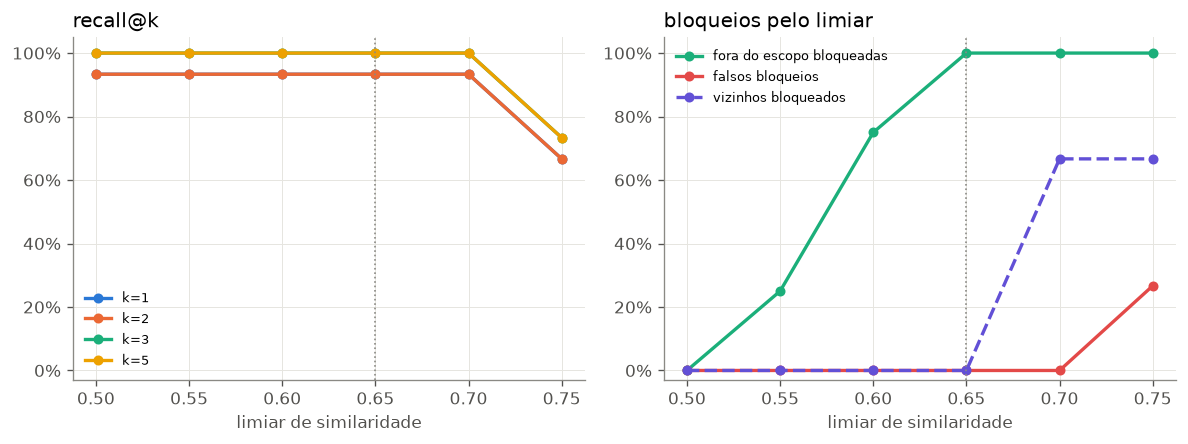

In [39]:
#@title G1 · Busca: recall e bloqueios por limiar
grade = pd.read_csv(bm.ARQ_BUSCA)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for i, (k, g) in enumerate(grade.groupby("top_k")):
    a1.plot(g.limiar, g["recall@k"], marker="o", ms=5, lw=2, color=SERIE_K[i], label=f"k={k}")
g = grade[grade.top_k == grade.top_k.min()]
a2.plot(g.limiar, g.fora_bloqueadas, marker="o", ms=5, lw=2, color="#1baf7a", label="fora do escopo bloqueadas")
a2.plot(g.limiar, g.falsos_bloqueios, marker="o", ms=5, lw=2, color="#e34948", label="falsos bloqueios")
a2.plot(g.limiar, g.vizinho_bloqueadas, marker="o", ms=5, lw=2, ls="--", color="#6250d6", label="vizinhos bloqueados")
for ax, t in ((a1, "recall@k"), (a2, "bloqueios pelo limiar")):
    ax.set_title(t, loc="left"); ax.yaxis.set_major_formatter(pct); ax.set_ylim(-0.03, 1.05); ax.set_xlabel("limiar de similaridade")
    ax.axvline(LIMIAR_ESCOLHIDO, color="#8a8984", lw=1, ls=":"); ax.legend(frameon=False, fontsize=8)
salvar(fig, "g1_busca_limiar")

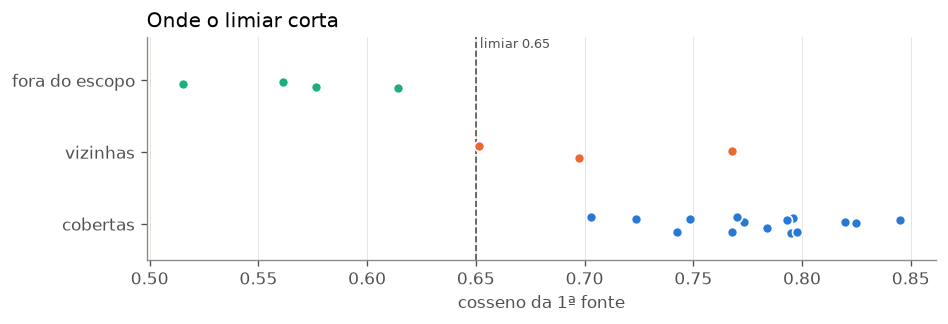

In [40]:
#@title G2 · Similaridade da 1ª fonte: perguntas cobertas × fora do escopo
det = pd.read_csv(bm.ARQ_BUSCA_DETALHE)
ordem = ["documentacao", "vizinho", "fora"]; rot = {"documentacao": "cobertas", "vizinho": "vizinhas", "fora": "fora do escopo"}
fig, ax = plt.subplots(figsize=(8, 2.8))
rng = np.random.default_rng(0)
for i, t in enumerate(ordem):
    v = det[det.tipo == t].sim_top1
    ax.scatter(v, i + rng.uniform(-0.12, 0.12, len(v)), s=36, color=SERIE_K[i], edgecolor="white", linewidth=1, zorder=3)
ax.axvline(LIMIAR_ESCOLHIDO, color="#52514e", lw=1, ls="--"); ax.text(LIMIAR_ESCOLHIDO, 2.45, f" limiar {LIMIAR_ESCOLHIDO:.2f}", fontsize=8, color="#52514e")
ax.set_yticks(range(len(ordem)), [rot[t] for t in ordem]); ax.set_ylim(-0.5, 2.6); ax.grid(axis="y", visible=False)
ax.set_xlabel("cosseno da 1ª fonte"); ax.set_title("Onde o limiar corta", loc="left")
salvar(fig, "g2_similaridade_top1")

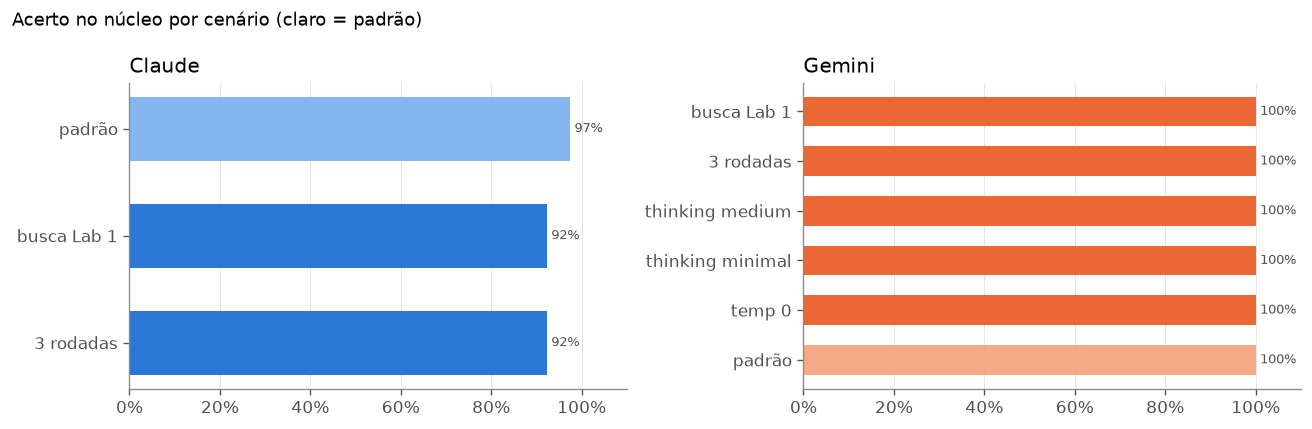

In [41]:
#@title G3 · Ajuste: acerto de cada cenário no núcleo
H = HIST_AJUSTE if "HIST_AJUSTE" in globals() else bm.resumo(bm.carregar_respostas().query("nucleo == True"))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, prov in zip(axs, ("anthropic", "gemini")):
    h = H[H.provedor == prov].sort_values("acerto")
    cores = [CLARO[prov] if "padrão" in n else COR[prov] for n in h.cenario]
    ax.barh(h.cenario.str.split(" · ").str[1], h.acerto, color=cores, height=0.6)
    for y, v in enumerate(h.acerto): ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color="#52514e")
    ax.set_title("Claude" if prov == "anthropic" else "Gemini", loc="left"); ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1.1)
    ax.grid(axis="y", visible=False)
fig.suptitle("Acerto no núcleo por cenário (claro = padrão)", x=0.01, ha="left", fontsize=11)
salvar(fig, "g3_ajuste_acerto")

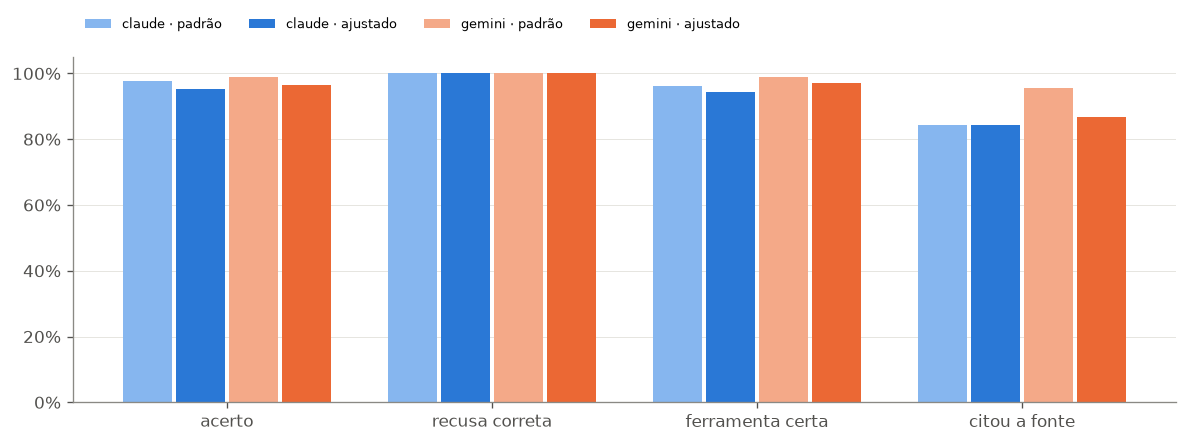

In [42]:
#@title G4 · Final: antes × depois por modelo, em cada métrica de qualidade
H = HIST_FINAL if "HIST_FINAL" in globals() else pd.read_csv(bm.SAIDA / "resumo_final.csv")
metricas = ["acerto", "recusa_correta", "ferramenta_certa", "citou_fonte"]
x = np.arange(len(metricas)); w = 0.2
fig, ax = plt.subplots(figsize=(10, 3.8))
for j, n in enumerate(FINAL):
    r = H[H.cenario == n].iloc[0]; prov = r.provedor
    ax.bar(x + (j - 1.5) * w, [r[m] for m in metricas], w * 0.92, label=n,
           color=CLARO[prov] if "padrão" in n else COR[prov])
ax.set_xticks(x, ["acerto", "recusa correta", "ferramenta certa", "citou a fonte"]); ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False); ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper left", bbox_to_anchor=(0, 1.15))
salvar(fig, "g4_final_qualidade")

/var/folders/v4/96y4kw3d4kxgn72q44kzbjrc0000gp/T/ipykernel_5219/4055864397.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a2.boxplot([d[d.cenario == n].latencia_s for n in FINAL], vert=False, widths=0.5, patch_artist=True,


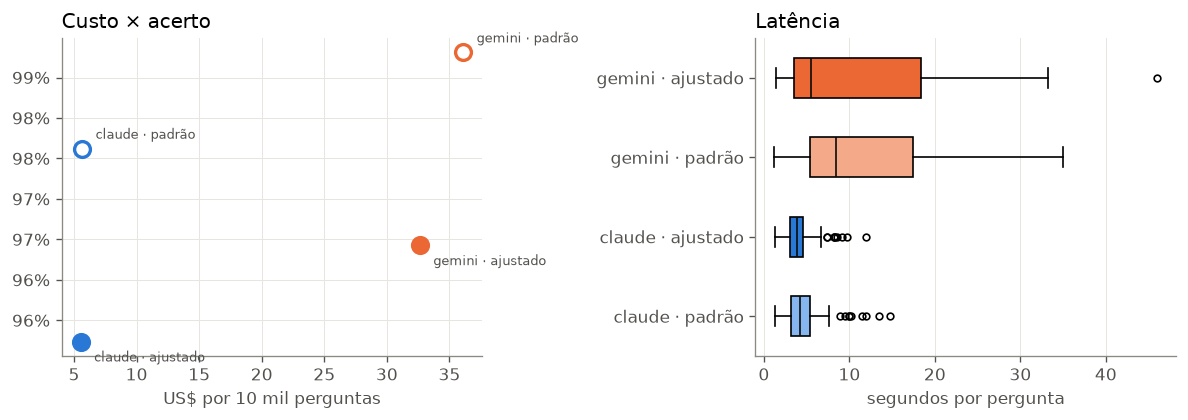

In [43]:
#@title G5 · Final: custo × acerto e latência
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for j, n in enumerate(FINAL):
    r = H[H.cenario == n].iloc[0]; prov = r.provedor; cheio = "padrão" not in n
    a1.scatter(r.custo_10mil_usd, r.acerto, s=90, color=COR[prov] if cheio else "white", edgecolor=COR[prov], linewidth=2, zorder=3)
    a1.annotate(n, (r.custo_10mil_usd, r.acerto), xytext=(8, 6 if j % 2 == 0 else -12), textcoords="offset points", fontsize=8, color="#52514e")
a1.set_xlabel("US$ por 10 mil perguntas"); a1.set_title("Custo × acerto", loc="left"); a1.yaxis.set_major_formatter(pct)
d = bm.carregar_respostas(); d = d[d.cenario.isin(FINAL) & d.erro.isna()]
bp = a2.boxplot([d[d.cenario == n].latencia_s for n in FINAL], vert=False, widths=0.5, patch_artist=True,
                medianprops=dict(color="#0b0b0b"), flierprops=dict(markersize=4))
for patch, n in zip(bp["boxes"], FINAL):
    prov = "anthropic" if n.startswith("claude") else "gemini"; patch.set_facecolor(CLARO[prov] if "padrão" in n else COR[prov])
a2.set_yticks(range(1, len(FINAL) + 1), FINAL); a2.set_xlabel("segundos por pergunta"); a2.set_title("Latência", loc="left")
a2.grid(axis="y", visible=False)
salvar(fig, "g5_final_custo_latencia")

---
# Levar o ajuste para o app
Os parâmetros são lidos de variáveis de ambiente ou de `.streamlit/secrets.toml` (`config.py`). Sem nada definido, vale a linha de base. Copie as linhas abaixo para os *secrets* do Streamlit Cloud.

Um ajuste vale para os dois provedores (`top_k`, limiar, rodadas, temperatura). Se os dois modelos pedirem valores diferentes, decida pelo modelo padrão do app (`RAG_PROVEDOR_PADRAO`) ou separe por provedor no código.

In [44]:
#@title Linhas para o secrets.toml
padrao_app = config.RAG_PROVEDOR_PADRAO
c = AJUSTADO["claude · ajustado" if padrao_app == "anthropic" else "gemini · ajustado"]
print(f"# ajuste do benchmark ({padrao_app})")
print(f'RAG_BUSCA_TOP_K = "{c.top_k}"')
print(f'RAG_LIMIAR_SIMILARIDADE = "{c.limiar:.2f}"')
print(f'RAG_MAX_RODADAS = "{c.max_rodadas}"')
print(f'RAG_TEMPERATURA = "{"" if c.temperatura is None else c.temperatura}"')
print(f'RAG_GEMINI_THINKING = "{AJUSTADO["gemini · ajustado"].thinking}"')

# ajuste do benchmark (anthropic)
RAG_BUSCA_TOP_K = "3"
RAG_LIMIAR_SIMILARIDADE = "0.65"
RAG_MAX_RODADAS = "6"
RAG_TEMPERATURA = ""
RAG_GEMINI_THINKING = "low"


🔵 **Limites desta avaliação** (vale dizer na apresentação)
* A verificação procura palavras e regras simples, como no curso. Ela erra às vezes: leia as respostas erradas antes de concluir. O próximo passo seria um LLM como juiz (encontro 7).
* ~35 perguntas escritas pela equipe. O intervalo de 95% mostra o tamanho do ruído; diferenças dentro dele não sustentam “um é melhor”.
* O gabarito de recall procura a evidência no texto do trecho. Se um documento for reescrito, revise `avaliacao/perguntas.py` (a célula de auditoria aponta perguntas sem trecho com a evidência).
* Preços em `bm.PRECOS` conferidos em nov/2026 (Claude Haiku 5.5: US$ 0,10/0,50; Gemini 3.5 Flash-Lite: US$ 0,30/2,50 por milhão de tokens; a saída do Gemini inclui o thinking). Os tokens ficam gravados para recalcular.
* O Gemini rodou com 1 repetição e o Claude com 3: a consistência só é medida no Claude.